# CONCH · Kimi R2 · Site shift at native resolution

All custom acquisition and analysis code is in this notebook. Use Python3.11 and the pinned CONCH library141cc09c7d4ff33d8eda562bd75169b457f71a62, torch2.5.0, torchvision0.20.0, open_clip_torch2.24.0, NumPy1.26.4, pandas2.2.2, sklearn1.5.2, scikit-image0.24.0 and Pillow10.4.0.

## 1. Data source / acquisition

Acquire the pinned CRC validation image shards. The resolution and site investigations also acquire the complete public NCT image inventory to select the seeded reference-training and confirmation panels. Model sources and weights are loaded explicitly in section4.

**Environment setup before starting the kernel (Linux, Python 3.11):**

Create this shared GPT/Kimi environment before opening the notebook. Keep it separate from the primary CONCH environment, which uses different numerical-library versions.

```bash
python3.11 -m venv .venv-conch-shared
.venv-conch-shared/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-shared/bin/python -m pip install numpy==1.26.4 scipy==1.13.1 pandas==2.2.2 scikit-learn==1.5.2 Pillow==10.4.0 pyarrow==16.1.0 scikit-image==0.24.0 statsmodels==0.14.2 opencv-python-headless==4.10.0.84
.venv-conch-shared/bin/python -m pip install matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open-clip-torch==2.24.0 requests==2.34.2 regex==2026.11.9 safetensors==0.8.0 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-shared/bin/python -m pip install --no-deps "git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62"
.venv-conch-shared/bin/python -m ipykernel install --user --name conch-gpt-kimi-inline --display-name "CONCH GPT/Kimi"
```

Select **CONCH GPT/Kimi** before Run All. The CUDA 12.4 wheels require a compatible NVIDIA driver; the code also selects CPU if CUDA is unavailable. Authenticate with Hugging Face using an account that can access `MahmoodLab/conch` before the checkpoint-download cell. The `huggingface-cli login` command is provided by the pinned Hub package.

The default input directory is `inputs/` below the notebook working directory. Set `CONCH_INPUTS` before starting the kernel to reuse a shared raw-input directory. The notebook verifies its declared downloaded inputs and runs the calculations shown below, including the stated scoring or eligibility diagnostic. All analysis-specific functions are inline; the installed CONCH package is the pinned public model implementation.

The reference models use OpenCLIP 2.24.0 (`ViT-B-32`, `laion2b_s34b_b79k`) and the public DINOv2 `dinov2_vitb14` implementation at revision `7764ea0f912e53c92e82eb78a2a1631e92725fc8`. Their released weights are fetched by the inline model cell. DINOv2 ran with standard PyTorch attention; `xformers` and the DINO training packages are not required. CONCH uses the public transform at its default 448×448 model-input size; the resolution intervention is applied to source images before this transform.


In [1]:
AXIS=3
CRC_SHARDS=['data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']

from pathlib import Path
import concurrent.futures,hashlib,io,json,os,shutil,time,zipfile
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
from huggingface_hub import hf_hub_download,hf_hub_url,get_hf_file_metadata
from sklearn.neighbors import NearestNeighbors,NearestCentroid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

INPUT=Path(os.environ.get('CONCH_INPUTS',Path.cwd()/'inputs'));INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'conch-kimi-r2-test-{AXIS:02}-outputs';OUT.mkdir(exist_ok=True)
CLASSES=['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
CLASS_MAP={'ADI':'ADI','BACK':'BACK','DEB':'DEB','LYM':'LYM','MUC':'MUC','MUS':'MUS','NORM':'NORM','STR':'STR','TUM':'TUM','NCS':'DEB','NOR':'NORM','FCT':'STR','BLD':None}
REVISION='97765ecb14bf11ce7bb8779a1097d187844a67cb'
SOURCE_REVISION='141cc09c7d4ff33d8eda562bd75169b457f71a62'
CHECKPOINT_REVISION='f9ca9f877171a28ade80228fb195ac5d79003357'
SEED=20260715

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as source:
        for block in iter(lambda:source.read(8<<20),b''):digest.update(block)
    return digest.hexdigest()

def show_figure(figure):
    output=io.BytesIO();figure.savefig(output,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=output.getvalue()));plt.close(figure)

def download(url,destination,expected_sha256=None,expected_bytes=None):
    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)
    if destination.is_file() and (expected_bytes is None or destination.stat().st_size==expected_bytes) and (expected_sha256 is None or sha256(destination)==expected_sha256):return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with requests.get(url,stream=True,timeout=120) as response:
        response.raise_for_status()
        with open(temporary,'wb') as target:
            for block in response.iter_content(8<<20):target.write(block)
    if expected_bytes is not None:assert temporary.stat().st_size==expected_bytes
    if expected_sha256 is not None:assert sha256(temporary)==expected_sha256
    temporary.replace(destination);return destination

def pinned_parquet(filename):
    url=hf_hub_url('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REVISION)
    metadata=get_hf_file_metadata(url)
    digest=metadata.etag.strip('"')
    assert len(digest)==64,'Expected a large-file SHA-256 identity'
    return download(url,INPUT/'hf_parquet'/filename,digest,metadata.size)


with concurrent.futures.ThreadPoolExecutor(max_workers=3) as pool:crc_paths=list(pool.map(pinned_parquet,CRC_SHARDS))
display(pd.DataFrame([dict(source='CRC-VAL',url=hf_hub_url('1aurent/NCT-CRC-HE',name,repo_type='dataset',revision=REVISION),sha256=sha256(path)) for name,path in zip(CRC_SHARDS,crc_paths)]))

from huggingface_hub import list_repo_files
nct_filenames=sorted(name for name in list_repo_files('1aurent/NCT-CRC-HE',repo_type='dataset',revision=REVISION) if name.startswith('data/NCT_CRC_HE_100K-') and name.endswith('.parquet'))
assert len(nct_filenames)==31
with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:nct_paths=list(pool.map(pinned_parquet,nct_filenames))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,source,url,sha256
0,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,fc4aa78c380802f27e59a70b2f2877dc3d2b82ddc2b800...
1,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,d607ebd6b861e3aec2ae2d457993f42222393abb9bdd99...
2,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,d733e143f0c984d24262d7b98d30669a885e7a6e3fcb46...


In [2]:
def save_image(raw,source,source_key,label):
    encoded_hash=hashlib.sha256(raw).hexdigest()
    path=INPUT/'raw_images'/source/(encoded_hash+'.image')
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists() or sha256(path)!=encoded_hash:
        temporary=path.with_name(path.name+f'.{os.getpid()}.part');temporary.write_bytes(raw);temporary.replace(path)
    return dict(cohort=source,source_key=source_key,tile_id=encoded_hash,path=str(path),raw_label=label,encoded_sha256=encoded_hash)

crc_rows=[]
for source_name,path in zip(CRC_SHARDS,crc_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            image=example['image'];label=CLASSES[int(example['label'])]
            source_key=f'{source_name}:{group}:{index}:{image.get("path","")}'
            crc_rows.append(save_image(image['bytes'],'CRC',source_key,label))

crc=pd.DataFrame(crc_rows)
crc['label']=crc.raw_label.map({name:index for index,name in enumerate(CLASSES)})
crc['file']=[row.source_key.rsplit(':',1)[-1] for row in crc.itertuples(index=False)]
random=np.random.RandomState(20260722);pilot=[]
for label in CLASSES:
    group=crc[crc.raw_label==label].sort_values('file').reset_index(drop=True)
    pilot.append(group.iloc[random.choice(len(group),100,replace=False)])
pilot=pd.concat(pilot,ignore_index=True)
assert pilot.encoded_sha256.is_unique
pilot.to_csv(OUT/'pilot_images.csv',index=False)
display(crc.groupby('raw_label').size().rename('CRC images'))

nct_rows=[]
for filename,path in zip(nct_filenames,nct_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            label=CLASSES[int(example['label'])];image=example['image'];key=Path(image.get('path') or f'{group}-{index}').name
            nct_rows.append(dict(source_file=filename,row_group=group,row_index=index,raw_label=label,file=key,image=image))
nct_inventory=pd.DataFrame(nct_rows)
random=np.random.RandomState(20260722);chosen=[]
for label in CLASSES:
    group=nct_inventory[nct_inventory.raw_label==label].sort_values('file').reset_index(drop=True)
    order=random.permutation(len(group))
    for split,indices in [('train_probe',order[:500]),('evaluation',order[500:900]),('buffer',order[900:1000])]:
        for record in group.iloc[indices].itertuples(index=False):
            row=save_image(record.image['bytes'],'NCT',f'{record.source_file}:{record.row_group}:{record.row_index}:{record.file}',label)
            row['split']=split;row['label']=CLASSES.index(label);row['file']=record.file;chosen.append(row)
nct=pd.DataFrame(chosen)
train=nct[nct.split=='train_probe'].reset_index(drop=True)
confirmation=nct[nct.split=='evaluation'].reset_index(drop=True)
assert set(train.tile_id).isdisjoint(confirmation.tile_id)
nct.to_csv(OUT/'nct_sample_manifest.csv',index=False)
display(nct.groupby(['split','raw_label']).size().unstack(fill_value=0))
del nct_inventory,nct_rows


raw_label
ADI     1338
BACK     847
DEB      339
LYM      634
MUC     1035
MUS      592
NORM     741
STR      421
TUM     1233
Name: CRC images, dtype: int64

raw_label,ADI,BACK,DEB,LYM,MUC,MUS,NORM,STR,TUM
split,,,,,,,,,
buffer,100,100,100,100,100,100,100,100,100
evaluation,400,400,400,400,400,400,400,400,400
train_probe,500,500,500,500,500,500,500,500,500


## 2. Data processing

Decode RGB images and retain the original tissue-class labels. The exploratory pilot samples100 tiles per class with seed20260722. NCT uses500/class for the frozen reference head,400/class for evaluation and100/class as unused buffer, selected without outcomes.

In [3]:
display(pilot.groupby('raw_label').size().rename('Pilot images'))
print('CRC encoded duplicates:',int(crc.encoded_sha256.duplicated().sum()))


raw_label
ADI     100
BACK    100
DEB     100
LYM     100
MUC     100
MUS     100
NORM    100
STR     100
TUM     100
Name: Pilot images, dtype: int64

CRC encoded duplicates: 0


## 3. Axis definition and level construction

Resolution changes use bicubic downsampling followed by bicubic restoration to the original image size. Stain changes multiply HED channels by seeded log-normal factors; the measured image change is mean absolute LAB difference. Site uses the two declared cohorts at native resolution and is not a continuous intervention.

In [4]:
def degrade_resolution(image,factor):
    if factor==1:return image.copy()
    width,height=image.size
    return image.resize((width//factor,height//factor),PILImage.Resampling.BICUBIC).resize((width,height),PILImage.Resampling.BICUBIC)

from skimage.color import rgb2hed,hed2rgb,rgb2lab
def stain_perturb(image,alpha,seed):
    if alpha==0:return image.copy(),0.0
    random=np.random.RandomState(seed)
    array=np.asarray(image,dtype=np.float32)/255
    stains=rgb2hed(array)
    scale=np.exp(random.normal(0,alpha,size=(1,1,3))).astype(np.float32)
    transformed=hed2rgb(np.clip(stains*scale,0,None))
    transformed=np.clip(transformed*255,0,255).astype(np.uint8)
    difference=float(np.abs(rgb2lab(array)-rgb2lab(transformed.astype(np.float32)/255)).mean())
    return PILImage.fromarray(transformed),difference

if AXIS==1:LEVELS=[1,2,3,4,6,8]
elif AXIS==2:LEVELS=[0,.1,.2,.4]
else:LEVELS=[1]
display(pd.DataFrame({'level':LEVELS,'definition':[f'bicubic downsample by {level}, then restore image size' if AXIS!=2 else f'HED log-scale standard deviation {level}' for level in LEVELS]}))


,level,definition
0,1,"bicubic downsample by 1, then restore image size"


## 4. Model results or released scores

Run the released CONCH and OpenCLIP encoders with the same CRC prompt ensemble. Neither encoder is fine-tuned. Resolution/site also train the displayed logistic head on frozen DINOv2 features from the NCT training split; evaluation images never fit this head.

In [5]:
import torch
import open_clip
from conch.open_clip_custom import create_model_from_pretrained,tokenize,get_tokenizer
from torchvision import transforms
from sklearn.linear_model import LogisticRegression
torch.set_num_threads(4)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
checkpoint=INPUT/'conch_checkpoint/pytorch_model.bin'
if not checkpoint.exists() or sha256(checkpoint)!='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c':
    checkpoint=Path(hf_hub_download('MahmoodLab/conch','pytorch_model.bin',revision=CHECKPOINT_REVISION))
assert sha256(checkpoint)=='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c'
prompts=download(f'https://raw.githubusercontent.com/mahmoodlab/CONCH/{SOURCE_REVISION}/prompts/crc100k_prompts_all_per_class.json',INPUT/'crc100k_prompts_all_per_class.json','5cac7ab39a593e10d053647842401eae00b94351bd33c5edcad29b17757343e2')
prompt=json.loads(prompts.read_text())['0']
conch,pre_conch=create_model_from_pretrained('conch_ViT-B-16',checkpoint_path=str(checkpoint))
conch=conch.to(DEVICE).eval()
openclip,_,pre_openclip=open_clip.create_model_and_transforms('ViT-B-32',pretrained='laion2b_s34b_b79k',cache_dir=str(INPUT/'openclip'))
openclip=openclip.to(DEVICE).eval()

@torch.inference_mode()
def text_features(model,tokenizer):
    embeddings=[]
    for label in CLASSES:
        texts=[template.replace('CLASSNAME',name) for name in prompt['classnames'][label] for template in prompt['templates']]
        encoded=model.encode_text(tokenizer(texts).to(DEVICE))
        encoded=encoded/encoded.norm(dim=-1,keepdim=True)
        embeddings.append(encoded.mean(dim=0))
    weights=torch.stack(embeddings)
    return weights/weights.norm(dim=-1,keepdim=True)

conch_tokenizer=get_tokenizer()
conch_weights=text_features(conch,lambda texts:tokenize(conch_tokenizer,texts))
openclip_weights=text_features(openclip,open_clip.get_tokenizer('ViT-B-32'))

def transformed_images(frame,level):
    images=[];distances=[]
    level_index=LEVELS.index(level)
    for index,path in enumerate(frame.path):
        with PILImage.open(path) as image:raw=image.convert('RGB')
        if AXIS==2:
            # Python's integer-tuple hash is stable; record the exact seed construction.
            image,difference=stain_perturb(raw,level,hash((index,level_index))%(2**31))
        else:image=degrade_resolution(raw,level);difference=np.nan
        images.append(image);distances.append(difference)
    return images,distances

@torch.inference_mode()
def zero_shot_predictions(model,preprocess,weights,images):
    logits=[]
    for start in range(0,len(images),48):
        batch=torch.stack([preprocess(image) for image in images[start:start+48]]).to(DEVICE)
        encoded=model.encode_image(batch)
        encoded=encoded/encoded.norm(dim=-1,keepdim=True)
        logits.append((100*encoded@weights.T).cpu().numpy())
    logits=np.concatenate(logits)
    return logits,logits.argmax(axis=1)


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/conch/open_clip_custom/factory.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental featur

/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/open_clip/factory.py:128: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpo

In [6]:
# Frozen public DINOv2 features plus a new logistic head trained only on NCT train_probe.
# Pin the public implementation revision as well as the named released weights.
DINO_REVISION='7764ea0f912e53c92e82eb78a2a1631e92725fc8'
torch.hub.set_dir(str(INPUT/'torch_hub'))
dino=torch.hub.load(f'facebookresearch/dinov2:{DINO_REVISION}','dinov2_vitb14',pretrained=True,trust_repo=True).to(DEVICE).eval()
pre_dino=transforms.Compose([transforms.Resize((224,224),interpolation=transforms.InterpolationMode.BICUBIC),transforms.ToTensor(),transforms.Normalize(mean=(.485,.456,.406),std=(.229,.224,.225))])

@torch.inference_mode()
def dino_features(images):
    result=[]
    for start in range(0,len(images),64):
        batch=torch.stack([pre_dino(image) for image in images[start:start+64]]).to(DEVICE)
        result.append(dino(batch).cpu().numpy())
    return np.concatenate(result)

native_train=[PILImage.open(path).convert('RGB') for path in train.path]
train_features=dino_features(native_train)
classifier=LogisticRegression(max_iter=2000,C=1,n_jobs=4).fit(train_features,train.label)
np.save(OUT/'dino_train_features.npy',train_features)
print('DINOv2 head training examples:',len(train),'native training accuracy:',classifier.score(train_features,train.label))
del native_train


Downloading: "https://github.com/facebookresearch/dinov2/zipball/7764ea0f912e53c92e82eb78a2a1631e92725fc8" to /ewsc/yektefai/spectra_runs/conch_nonprimary_reconstruction_20261109/inputs/torch_hub/7764ea0f912e53c92e82eb78a2a1631e92725fc8.zip


/ewsc/yektefai/spectra_runs/conch_nonprimary_reconstruction_20261109/inputs/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/ewsc/yektefai/spectra_runs/conch_nonprimary_reconstruction_20261109/inputs/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/ewsc/yektefai/spectra_runs/conch_nonprimary_reconstruction_20261109/inputs/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /ewsc/yektefai/spectra_runs/conch_nonprimary_reconstruction_20261109/inputs/torch_hub/checkpoints/dinov2_vitb14_pretrain.pth


  0%|          | 0.00/330M [00:00<?, ?B/s]

 12%|█▏        | 38.6M/330M [00:00<00:00, 403MB/s]

 24%|██▍       | 80.9M/330M [00:00<00:00, 426MB/s]

... (3 outputs left out)

 81%|████████  | 267M/330M [00:00<00:00, 487MB/s]

 97%|█████████▋| 319M/330M [00:00<00:00, 507MB/s]

100%|██████████| 330M/330M [00:00<00:00, 478MB/s]

DINOv2 head training examples: 4500 native training accuracy: 1.0


In [7]:
panels={'CRC pilot':pilot} if AXIS==2 else {'NCT confirmation':confirmation,'CRC validation':crc}
rows=[];axis_measurements=[]
from skimage.metrics import structural_similarity
for cohort,frame in panels.items():
    frame=frame.reset_index(drop=True)
    if AXIS!=2:
        native_images=[PILImage.open(path).convert('RGB') for path in frame.path]
        native_features=dino_features(native_images)
        native_normalized=native_features/np.linalg.norm(native_features,axis=1,keepdims=True)
    for level in LEVELS:
        images,differences=transformed_images(frame,level)
        for name,model,preprocess,weights in [('CONCH',conch,pre_conch,conch_weights),('OpenCLIP',openclip,pre_openclip,openclip_weights)]:
            logits,predicted=zero_shot_predictions(model,preprocess,weights,images)
            np.save(OUT/f'{cohort.replace(" ","_")}_{name}_level{level}_logits.npy',logits)
            for tile,true,prediction in zip(frame.tile_id,frame.label,predicted):rows.append(dict(cohort=cohort,tile_id=tile,label=int(true),method=name,level=level,prediction=int(prediction)))
        if AXIS!=2:
            features=dino_features(images)
            predicted=classifier.predict(features)
            for tile,true,prediction in zip(frame.tile_id,frame.label,predicted):rows.append(dict(cohort=cohort,tile_id=tile,label=int(true),method='DINOv2 logistic',level=level,prediction=int(prediction)))
            normalized=features/np.linalg.norm(features,axis=1,keepdims=True)
            cos=float((normalized*native_normalized).sum(axis=1).mean())
            ssim=float(np.mean([structural_similarity(np.asarray(a),np.asarray(b),channel_axis=2,data_range=255) for a,b in zip(native_images[:300],images[:300])]))
            axis_measurements.append(dict(cohort=cohort,level=level,cosine_to_native=cos,ssim_to_native=ssim))
        else:axis_measurements.append(dict(cohort=cohort,level=level,mean_LAB_absolute_difference=float(np.mean(differences))))
        print(cohort,'level',level,'scored',len(frame),'images',flush=True)
predictions=pd.DataFrame(rows);measurements=pd.DataFrame(axis_measurements)
predictions.to_csv(OUT/'per_image_predictions.csv.gz',index=False)
measurements.to_csv(OUT/'axis_measurements.csv',index=False)
display(measurements)


NCT confirmation level 1 scored 3600 images


CRC validation level 1 scored 7180 images


,cohort,level,cosine_to_native,ssim_to_native
0,NCT confirmation,1,1.0,1.0
1,CRC validation,1,1.0,1.0


## 5. Curves and controls

Compute class-balanced accuracy, class-stratified tile bootstrap intervals, paired native-minus-most-degraded contrasts, and per-class results. Resolution ordering is checked with SSIM and DINOv2 similarity to each image’s native form. Fixed reference models use identical images and levels.

/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1762: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1762: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


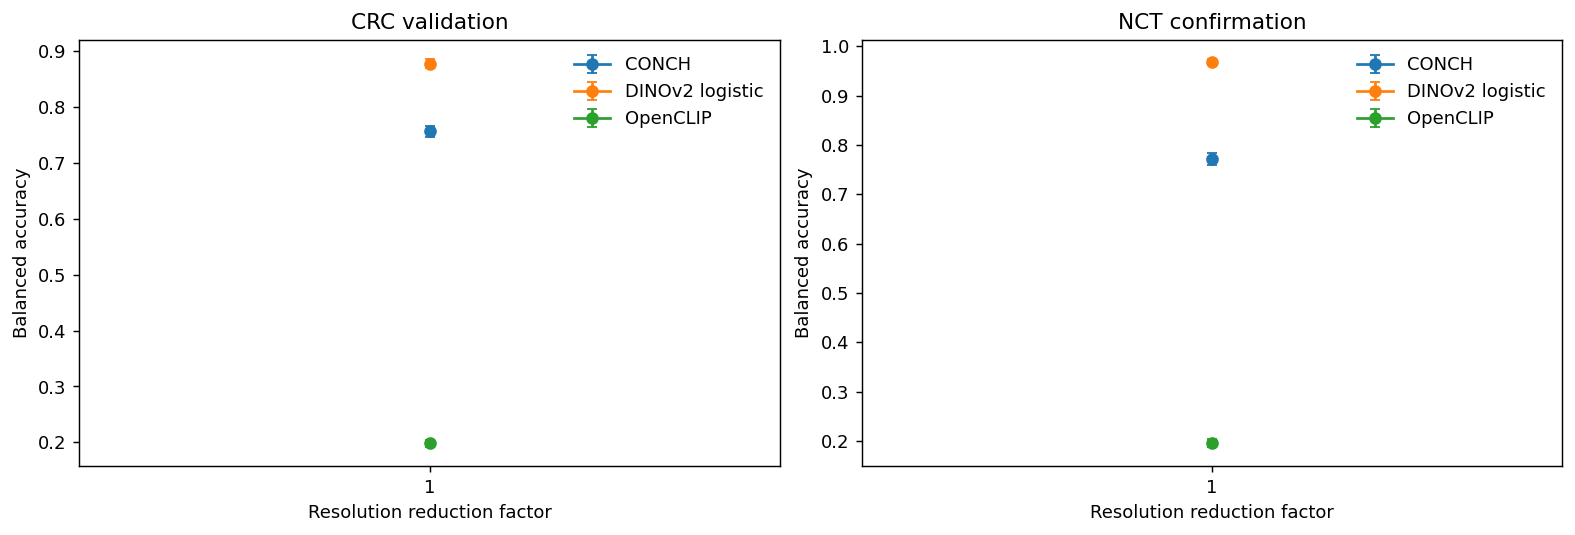

,cohort,method,level,balanced_accuracy,low,high,n_images
0,CRC validation,CONCH,1,0.756350,0.746345,0.766923,7180
1,CRC validation,DINOv2 logistic,1,0.877859,0.869642,0.885977,7180
2,CRC validation,OpenCLIP,1,0.198071,0.191895,0.204185,7180
3,NCT confirmation,CONCH,1,0.771389,0.758889,0.783889,3600
4,NCT confirmation,DINOv2 logistic,1,0.968611,0.962500,0.974167,3600
5,NCT confirmation,OpenCLIP,1,0.196389,0.188333,0.205000,3600


""


level                                          1
cohort           method          label          
CRC validation   CONCH           ADI    0.866966
                                 BACK   0.945691
                                 DEB    0.684366
                                 LYM    0.993691
                                 MUC    0.909179
                                 MUS    0.891892
                                 NORM   0.519568
                                 STR    0.439430
                                 TUM    0.556367
                 DINOv2 logistic ADI    0.987294
                                 BACK   0.995277
                                 DEB    0.840708
                                 LYM    0.990536
                                 MUC    0.930435
                                 MUS    0.876689
                                 NORM   0.951417
                                 STR    0.403800
                                 TUM    0.924574
                 OpenCLIP        ADI    0.100897
                                 BACK   0.303424
                                 DEB    0.002950
                                 LYM    0.009464
                                 MUC    0.000000
                                 MUS    0.342905
                                 NORM   0.049933
                                 STR    0.007126
                                 TUM    0.965937
NCT confirmation CONCH           ADI    0.710000
                                 BACK   0.972500
                                 DEB    0.832500
                                 LYM    0.982500
                                 MUC    0.880000
                                 MUS    0.885000
                                 NORM   0.390000
                                 STR    0.482500
                                 TUM    0.807500
                 DINOv2 logistic ADI    0.980000
                                 BACK   0.995000
                                 DEB    0.947500
                                 LYM    0.997500
                                 MUC    0.965000
                                 MUS    0.945000
                                 NORM   0.962500
                                 STR    0.945000
                                 TUM    0.980000
                 OpenCLIP        ADI    0.132500
                                 BACK   0.415000
                                 DEB    0.000000
                                 LYM    0.005000
                                 MUC    0.000000
                                 MUS    0.212500
                                 NORM   0.012500
                                 STR    0.000000
                                 TUM    0.990000

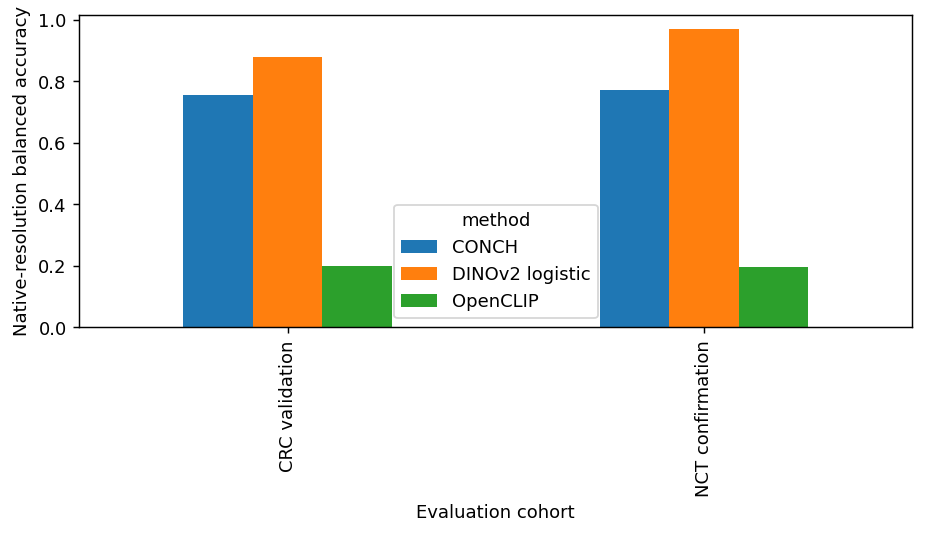

In [8]:
def class_bootstrap(frame,rng,repeats=2000):
    result=np.zeros(repeats)
    for _,group in frame.groupby('label'):
        correct=(group.prediction==group.label).to_numpy(dtype=float)
        for start in range(0,repeats,100):
            stop=min(start+100,repeats);sample=rng.integers(0,len(correct),(stop-start,len(correct)))
            result[start:stop]+=correct[sample].mean(axis=1)
    return result/frame.label.nunique()
random=np.random.default_rng(20260722);curve_rows=[];effect_rows=[];within_rows=[]
for (cohort,method),frame in predictions.groupby(['cohort','method']):
    for level,group in frame.groupby('level'):
        recalls=group.assign(correct=(group.prediction==group.label).astype(float)).groupby('label').correct.mean()
        bootstrap=class_bootstrap(group,random);low,high=np.quantile(bootstrap,[.025,.975])
        curve_rows.append(dict(cohort=cohort,method=method,level=level,balanced_accuracy=recalls.mean(),low=low,high=high,n_images=len(group)))
        for label,recall in recalls.items():within_rows.append(dict(cohort=cohort,method=method,level=level,label=CLASSES[label],recall=recall))
    if len(LEVELS)>1:
        wide=frame.pivot(index=['tile_id','label'],columns='level',values='prediction')
        differences=((wide[min(LEVELS)].to_numpy()==wide.index.get_level_values('label')).astype(float)-(wide[max(LEVELS)].to_numpy()==wide.index.get_level_values('label')).astype(float))
        paired=pd.DataFrame({'label':wide.index.get_level_values('label'),'difference':differences})
        boot=np.zeros(2000)
        for _,group in paired.groupby('label'):
            values=group.difference.to_numpy()
            for start in range(0,2000,100):boot[start:start+100]+=values[random.integers(0,len(values),(100,len(values)))].mean(axis=1)
        boot/=paired.label.nunique();low,high=np.quantile(boot,[.025,.975])
        effect_rows.append(dict(cohort=cohort,method=method,drop=paired.groupby('label').difference.mean().mean(),low=low,high=high))
curves=pd.DataFrame(curve_rows);effects=pd.DataFrame(effect_rows);within=pd.DataFrame(within_rows)
curves.to_csv(OUT/'curves.csv',index=False);effects.to_csv(OUT/'paired_effects.csv',index=False);within.to_csv(OUT/'within_class.csv',index=False)
fig,axes=plt.subplots(1,curves.cohort.nunique(),figsize=(6*curves.cohort.nunique(),4),squeeze=False,constrained_layout=True)
for ax,(cohort,frame) in zip(axes.ravel(),curves.groupby('cohort')):
    for method,group in frame.groupby('method'):
        ax.errorbar(group.level,group.balanced_accuracy,yerr=[group.balanced_accuracy-group.low,group.high-group.balanced_accuracy],marker='o',capsize=3,label=method)
    ax.set(title=cohort,xlabel='HED perturbation strength' if AXIS==2 else 'Resolution reduction factor',ylabel='Balanced accuracy',xticks=LEVELS);ax.legend(frameon=False)
show_figure(fig);display(curves);display(effects)
display(within.pivot(index=['cohort','method','label'],columns='level',values='recall'))
if AXIS==3:
    fig,ax=plt.subplots(figsize=(7,4),constrained_layout=True)
    table=curves.pivot(index='cohort',columns='method',values='balanced_accuracy');table.plot.bar(ax=ax)
    ax.set(ylabel='Native-resolution balanced accuracy',xlabel='Evaluation cohort');show_figure(fig)


## 6. Decision and reason

In [9]:
display(Markdown('**Retain cohort/site as a descriptive control.** The native-resolution results compare the declared NCT and CRC panels. They do not isolate a causal site effect because sampling and image composition can differ between cohorts.'))
display(curves)


**Retain cohort/site as a descriptive control.** The native-resolution results compare the declared NCT and CRC panels. They do not isolate a causal site effect because sampling and image composition can differ between cohorts.

,cohort,method,level,balanced_accuracy,low,high,n_images
0,CRC validation,CONCH,1,0.756350,0.746345,0.766923,7180
1,CRC validation,DINOv2 logistic,1,0.877859,0.869642,0.885977,7180
2,CRC validation,OpenCLIP,1,0.198071,0.191895,0.204185,7180
3,NCT confirmation,CONCH,1,0.771389,0.758889,0.783889,3600
4,NCT confirmation,DINOv2 logistic,1,0.968611,0.962500,0.974167,3600
5,NCT confirmation,OpenCLIP,1,0.196389,0.188333,0.205000,3600


In [10]:
manifest=[dict(path=p.name,bytes=p.stat().st_size,sha256=sha256(p)) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='OUTPUT_MANIFEST.json'];(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(manifest,indent=2));print('Outputs:',OUT.resolve())


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/conch-kimi-r2/conch-kimi-r2-test-03-outputs
